<a href="https://colab.research.google.com/github/7mid056/7mid056/blob/main/extrovert_and_introvert_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [71]:

import kagglehub
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# Download latest version
path = kagglehub.dataset_download("rakeshkapilavai/extrovert-vs-introvert-behavior-data")

print("Path to dataset files:",path)

Using Colab cache for faster access to the 'extrovert-vs-introvert-behavior-data' dataset.
Path to dataset files: /kaggle/input/extrovert-vs-introvert-behavior-data


In [72]:
csv_path = os.path.join(path,"personality_datasert.csv")
df = pd.read_csv(csv_path)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2900 entries, 0 to 2899
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Time_spent_Alone           2900 non-null   float64
 1   Stage_fear                 2900 non-null   object 
 2   Social_event_attendance    2900 non-null   float64
 3   Going_outside              2900 non-null   float64
 4   Drained_after_socializing  2900 non-null   object 
 5   Friends_circle_size        2900 non-null   float64
 6   Post_frequency             2900 non-null   float64
 7   Personality                2900 non-null   object 
dtypes: float64(5), object(3)
memory usage: 181.4+ KB


In [73]:
def check_duplicates(df):
  duplicates = df.duplicated().sum()
  print(f"Number of Duplicate Samples: {duplicates}")
  if duplicates > 0:
    print("Dropping Duplicates...")
    df.drop_duplicates(inplace=True)
    print("Duplicates Dropped.")
  else:
    print("No Duplicate Samples Found.")
check_duplicates(df)
df.info()

Number of Duplicate Samples: 402
Dropping Duplicates...
Duplicates Dropped.
<class 'pandas.core.frame.DataFrame'>
Index: 2498 entries, 0 to 2899
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Time_spent_Alone           2498 non-null   float64
 1   Stage_fear                 2498 non-null   object 
 2   Social_event_attendance    2498 non-null   float64
 3   Going_outside              2498 non-null   float64
 4   Drained_after_socializing  2498 non-null   object 
 5   Friends_circle_size        2498 non-null   float64
 6   Post_frequency             2498 non-null   float64
 7   Personality                2498 non-null   object 
dtypes: float64(5), object(3)
memory usage: 175.6+ KB


In [74]:

# 1. Is the target imbalanced?


Personality
Extrovert    0.561649
Introvert    0.438351
Name: proportion, dtype: float64


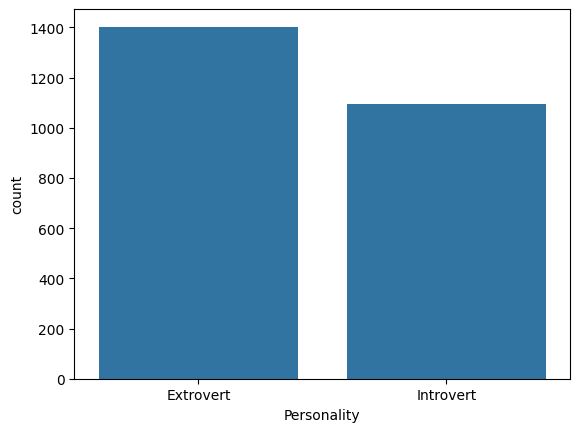

In [75]:
def check_target_imbalance(df,target_column):
  print(df[target_column].value_counts(normalize = True))
  sns.countplot(x=df[target_column])
  plt.show
check_target_imbalance(df,"Personality")

In [76]:
df.describe()

,Time_spent_Alone,Social_event_attendance,Going_outside,Friends_circle_size,Post_frequency
count,2498.000000,2498.000000,2498.000000,2498.000000,2498.000000
mean,4.232128,4.200867,3.192954,6.580130,3.815283
std,3.406630,2.874305,2.218807,4.257516,2.914253
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,2.000000,1.000000,3.000000,1.000000
50%,3.000000,4.000000,3.000000,6.000000,3.000000
75%,7.000000,7.000000,5.000000,10.000000,6.000000
max,11.000000,10.000000,7.000000,15.000000,10.000000


encoding the objects and catogoricals with label bcuz its binary and
use for col in df.select_dtypes(include =[object]).columns:
must use fit_transform

In [77]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
for col in df.select_dtypes(include =["object"]).columns:
  df[col] = le.fit_transform(df[col])

df

,Time_spent_Alone,Stage_fear,Social_event_attendance,Going_outside,Drained_after_socializing,Friends_circle_size,Post_frequency,Personality
0,4.0,0,4.0,6.0,0,13.0,5.000000,0
1,9.0,1,0.0,0.0,1,0.0,3.000000,1
2,9.0,1,1.0,2.0,1,5.0,2.000000,1
3,0.0,0,6.0,7.0,0,14.0,8.000000,0
4,3.0,0,9.0,4.0,0,8.0,5.000000,0
...,...,...,...,...,...,...,...,...
2894,0.0,0,9.0,3.0,0,12.0,3.564727,0
2896,3.0,0,8.0,3.0,0,14.0,9.000000,0
2897,4.0,1,1.0,1.0,1,4.0,0.000000,1
2898,11.0,1,1.0,3.0,1,2.0,0.000000,1


In [78]:
assigning the x and y of the data now

SyntaxError: invalid syntax (2848069743.py, line 1)

In [79]:

x = df.drop('Personality', axis =1)
y = df['Personality']

def binary_cross_entropy(y, y_hat):
  epsilon = 1e-15  # Very small number to prevent log(0)
  y_hat = np.clip(y_hat, epsilon, 1 - epsilon) # np.clip(value, min, max)

  loss = -1/len(y) * np.sum(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))
  return loss



In [80]:
def gradient_descent(X, y, learning_rate, n_iters=500):
  m, n = X.shape # m rows, n columns (dimensions)
  theta = np.zeros(n) # initialize a zeros weight vector with n dimensions
  losses = []

  for _ in tqdm(range(n_iters), desc="Training Logistic Regression"):
    z = np.dot(X, theta)
    y_hat = sigmoid(z)
    gradient = np.dot(X.T, (y_hat - y)) / m
    theta -= learning_rate * gradient

    loss = binary_cross_entropy(y, y_hat)
    losses.append(loss)

  return theta, losses

In [81]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from tqdm import tqdm
def sigmoid(z):
  return 1 / (1 + np.exp(-z))

In [82]:
n_splits = 5 # K=5 Folds

# Stratified 5-Fold Cross-Validation, shuffled
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)


# Storage for logistic regression results for each fold
lr_losses = []
lr_accuracy = []
lr_precision = []
lr_recall = []
lr_f1 = []

In [85]:
for fold_idx, (train_index, test_index) in enumerate(skf.split(x, y)):
    print(f"\nFold {fold_idx + 1}/{n_splits}")

    X_train, X_test = x.iloc[train_index], x.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    # Train
    theta, losses = gradient_descent(X_train, y_train, learning_rate=0.2, n_iters=300)

    # Validate
    y_pred_proba = sigmoid(np.dot(X_test, theta))
    y_pred = (y_pred_proba >= 0.5).astype(int)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    # Store results
    lr_losses.append(losses)
    lr_accuracy.append(accuracy)
    lr_precision.append(precision)
    lr_recall.append(recall)
    lr_f1.append(f1)


Fold 1/5


Training Logistic Regression: 100%|██████████| 300/300 [00:00<00:00, 1306.62it/s]



Fold 2/5


Training Logistic Regression: 100%|██████████| 300/300 [00:00<00:00, 1262.66it/s]



Fold 3/5


Training Logistic Regression: 100%|██████████| 300/300 [00:00<00:00, 1274.91it/s]



Fold 4/5


Training Logistic Regression: 100%|██████████| 300/300 [00:00<00:00, 1251.90it/s]



Fold 5/5


Training Logistic Regression: 100%|██████████| 300/300 [00:00<00:00, 1254.99it/s]


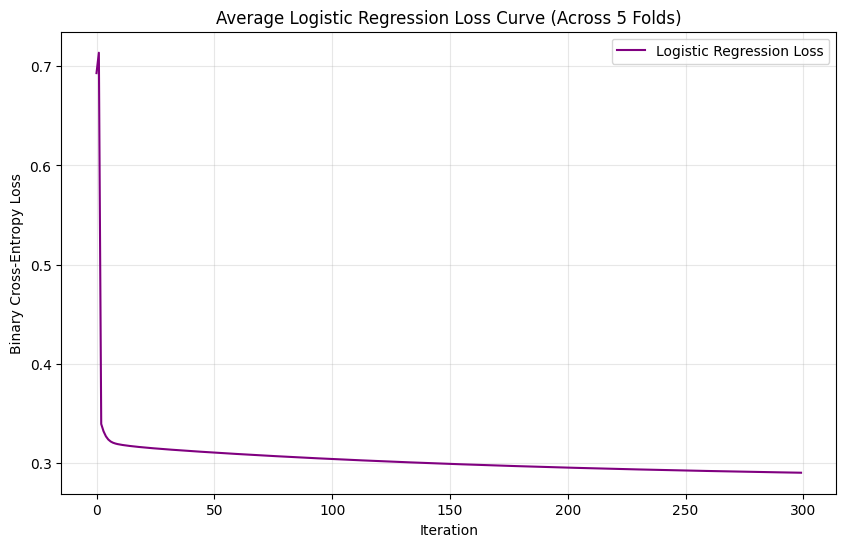

In [86]:
avg_loss = np.mean(lr_losses, axis=0)

plt.figure(figsize=(10, 6))
plt.plot(avg_loss, label='Logistic Regression Loss', color='purple')
plt.title('Average Logistic Regression Loss Curve (Across 5 Folds)')
plt.xlabel('Iteration')
plt.ylabel('Binary Cross-Entropy Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [ ]:
# لمعرفة أنواع البيانات في كل عمود والتأكد من أنها أرقام (int أو float)
print(df.dtypes)

# للتأكد من أن جميع القيم عبارة عن قيم مفردة وليست قوائم (Lists)
for col in df.columns:
    print(col, df[col].apply(type).unique())

Time_spent_Alone             float64
Stage_fear                     int64
Social_event_attendance      float64
Going_outside                float64
Drained_after_socializing      int64
Friends_circle_size          float64
Post_frequency               float64
Personality                    int64
dtype: object
Time_spent_Alone [<class 'float'>]
Stage_fear [<class 'int'>]
Social_event_attendance [<class 'float'>]
Going_outside [<class 'float'>]
Drained_after_socializing [<class 'int'>]
Friends_circle_size [<class 'float'>]
Post_frequency [<class 'float'>]
Personality [<class 'int'>]


In [87]:

print("LOGISTIC REGRESSION Performance:")
print(f"  Accuracy:  {np.mean(lr_accuracy):.4f}")
print(f"  Precision: {np.mean(lr_precision):.4f}")
print(f"  Recall:    {np.mean(lr_recall):.4f}")
print(f"  F1-Score:  {np.mean(lr_f1):.4f}")

LOGISTIC REGRESSION Performance:
  Accuracy:  0.9267
  Precision: 0.9065
  Recall:    0.9288
  F1-Score:  0.9174
